Saving image.jpg to image.jpg


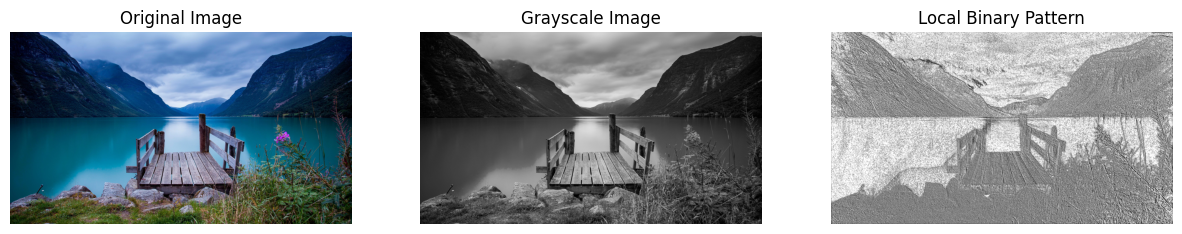

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload normal image
uploaded = files.upload()

# Read uploaded image
img = cv2.imread(list(uploaded.keys())[0])

# Convert RGB image to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Create LBP image
lbp = np.zeros_like(gray, dtype=np.uint8)

# Apply LBP
for i in range(1, gray.shape[0] - 1):
    for j in range(1, gray.shape[1] - 1):

        center = gray[i, j]

        neighbors = [
            gray[i-1, j-1], gray[i-1, j],
            gray[i-1, j+1], gray[i, j+1],
            gray[i+1, j+1], gray[i+1, j],
            gray[i+1, j-1], gray[i, j-1]
        ]

        binary = 0

        for k in range(8):
            if neighbors[k] >= center:
                binary += 2**k

        lbp[i, j] = binary

# Display images
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(lbp, cmap="gray")
plt.title("Local Binary Pattern")
plt.axis("off")

plt.show()

Saving image.jpg to image (3).jpg


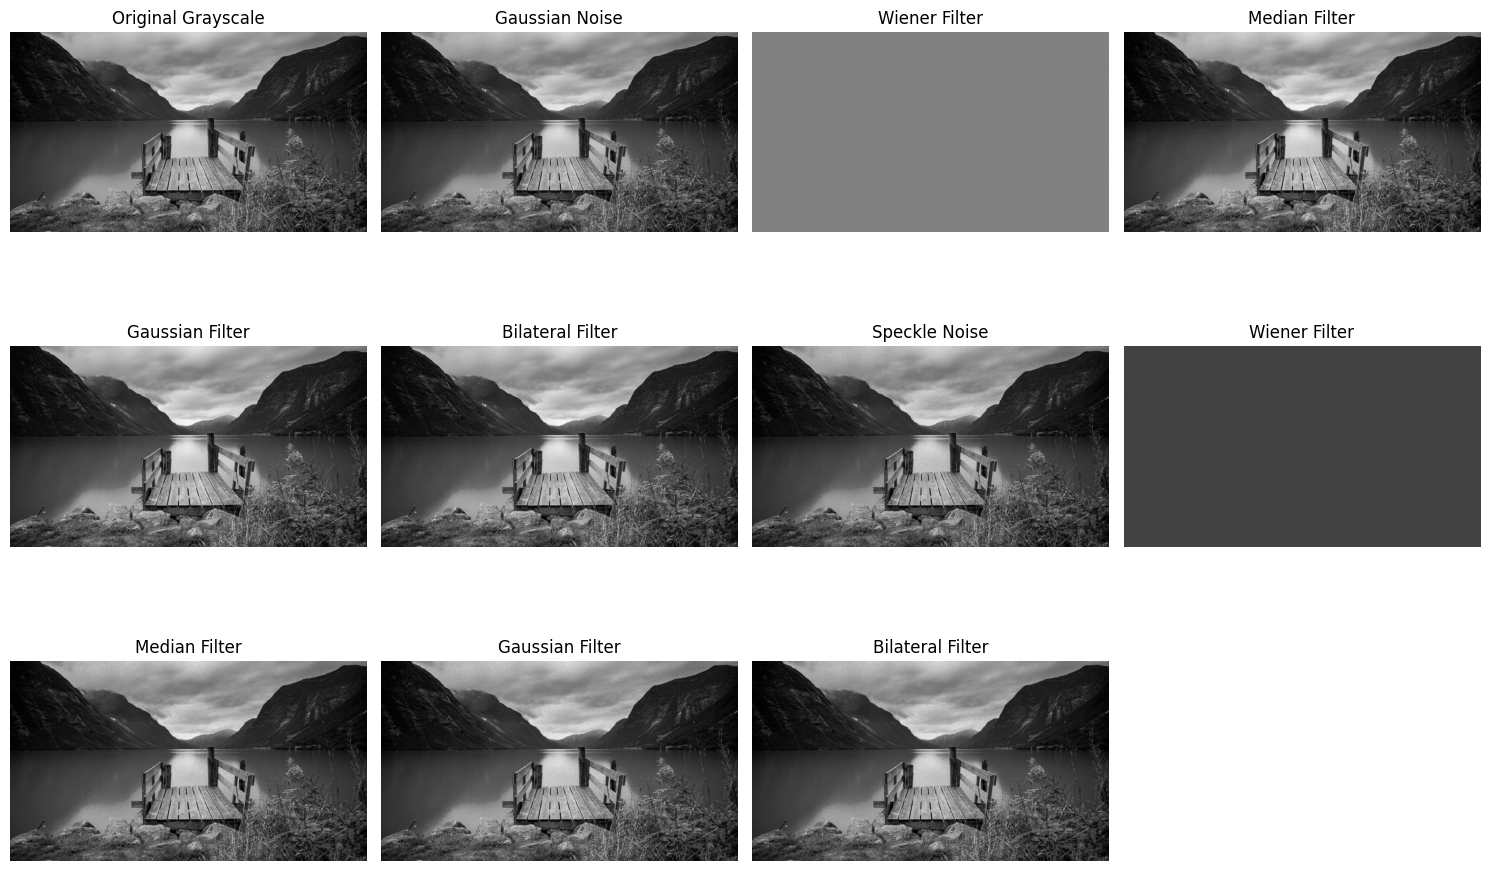

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from scipy.signal import wiener

# Upload image
uploaded = files.upload()

# Read image
img = cv2.imread(list(uploaded.keys())[0])

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

gray = gray.astype(np.float32) / 255.0

# Add Gaussian noise
gaussian_noise = gray + np.random.normal(0, 0.05, gray.shape)
gaussian_noise = np.clip(gaussian_noise, 0, 1)

# Add Speckle noise
speckle_noise = gray + gray * np.random.normal(0, 0.2, gray.shape)
speckle_noise = np.clip(speckle_noise, 0, 1)

# Convert to uint8
gaussian_img = (gaussian_noise * 255).astype(np.uint8)
speckle_img = (speckle_noise * 255).astype(np.uint8)

# (a) Wiener Filter
wiener_gaussian = wiener(gaussian_img, (5, 5))
wiener_speckle = wiener(speckle_img, (5, 5))

# (b) Median Filter
median_gaussian = cv2.medianBlur(gaussian_img, 5)
median_speckle = cv2.medianBlur(speckle_img, 5)

# (c) Gaussian Filter
gaussian_filtered = cv2.GaussianBlur(gaussian_img, (5, 5), 0)
speckle_filtered = cv2.GaussianBlur(speckle_img, (5, 5), 0)

# (d) Bilateral Filter
bilateral_gaussian = cv2.bilateralFilter(gaussian_img, 5, 75, 75)
bilateral_speckle = cv2.bilateralFilter(speckle_img, 5, 75, 75)

# Display results
plt.figure(figsize=(15, 10))

images = [
    gray, gaussian_img, wiener_gaussian,
    median_gaussian, gaussian_filtered, bilateral_gaussian,
    speckle_img, wiener_speckle, median_speckle,
    speckle_filtered, bilateral_speckle
]

titles = [
    "Original Grayscale", "Gaussian Noise", "Wiener Filter",
    "Median Filter", "Gaussian Filter", "Bilateral Filter",
    "Speckle Noise", "Wiener Filter", "Median Filter",
    "Gaussian Filter", "Bilateral Filter"
]

for i in range(len(images)):
    plt.subplot(3, 4, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()